In [ ]:
# =============================================================================
# CELL 1 -- Google Colab Drive Mounting
# =============================================================================

from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
# =============================================================================
# CELL 2 -- Dependencies Installation
# =============================================================================

import subprocess
subprocess.run(
    ['pip', 'install', 'pytorch-lightning', 'wandb', 'scikit-learn', '-q'],
    check=True,
)

CompletedProcess(args=['pip', 'install', 'pytorch-lightning', 'wandb', 'scikit-learn', '-q'], returncode=0)

In [ ]:
# =============================================================================
# CELL 3 -- Path Configuration & Import Path Resolution
# =============================================================================

import sys
import shutil
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/MP2')
PKL_PATH     = Path('/content/drive/MyDrive/MP2/data/new2.pkl')

assert PROJECT_ROOT.exists(), f"Project root not found: {PROJECT_ROOT}"
assert PKL_PATH.exists(),     f"Pickle not found: {PKL_PATH}"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

CKPT_DIR = PROJECT_ROOT / 'outputs' / 'checkpoints'
FIG_DIR  = PROJECT_ROOT / 'outputs' / 'figures'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True,  exist_ok=True)

print('Project root  :', PROJECT_ROOT)
print('Pickle path   :', PKL_PATH)
print('Checkpoint dir:', CKPT_DIR)

Project root  : /content/drive/MyDrive/MP2
Pickle path   : /content/drive/MyDrive/MP2/data/new2.pkl
Checkpoint dir: /content/drive/MyDrive/MP2/outputs/checkpoints


In [ ]:
# =============================================================================
# CELL 4 -- Library Imports & Initialization
# =============================================================================

import numpy as np
import torch
import pytorch_lightning as pl
from pytorch_lightning.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    LearningRateMonitor,
)
from pytorch_lightning.loggers import WandbLogger
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

# Project imports -- resolved from PROJECT_ROOT on Drive
from src.data_load.dataloader    import get_all_dataloaders
from src.models.multimodal_model import MultimodalICUModel
from src.training.metrics import (
    compute_los_metrics,
    compute_mortality_metrics,
    ordinal_logits_to_band,
    print_classification_report,
)

print('PyTorch Lightning:', pl.__version__)
print('PyTorch          :', torch.__version__)
print('GPU available    :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name         :', torch.cuda.get_device_name(0))
print('All imports OK')

PyTorch Lightning: 2.6.1
PyTorch          : 2.10.0+cu128
GPU available    : True
GPU name         : Tesla T4
All imports OK


In [ ]:
# =============================================================================
# CELL 5 -- DataLoaders Instantiation & Batch Verification
# =============================================================================

from torch.utils.data import DataLoader, WeightedRandomSampler

BATCH_SIZE  = 64
NUM_WORKERS = 0      # 0 avoids worker subprocess import issues on Colab
PIN_MEMORY  = True

train_dataset = ICUDataset(str(PKL_PATH), split="train")
val_dataset   = ICUDataset(str(PKL_PATH), split="val")
test_dataset  = ICUDataset(str(PKL_PATH), split="test")

# WeightedRandomSampler for training
sampler = WeightedRandomSampler(
    weights     = train_dataset.sample_weights,
    num_samples = len(train_dataset),
    replacement = True,
)

train_loader = DataLoader(
    train_dataset,
    batch_size  = BATCH_SIZE,
    sampler     = sampler,
    num_workers = NUM_WORKERS,
    pin_memory  = PIN_MEMORY,
)
val_loader = DataLoader(
    val_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = NUM_WORKERS,
    pin_memory  = PIN_MEMORY,
)
test_loader = DataLoader(
    test_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = NUM_WORKERS,
    pin_memory  = PIN_MEMORY,
)

print(f'Train batches        : {len(train_loader)}')
print(f'Val   batches        : {len(val_loader)}')
print(f'Test  batches        : {len(test_loader)}')
print(f'Tabular features     : {train_dataset.n_tabular_features}')
print(f'Vital channels       : {train_dataset.n_vital_channels}')
print(f'LOS boundary weights : {train_dataset.los_boundary_weights}')
print(f'Mortality pos_weight : {train_dataset.mortality_pos_weight:.4f}')

batch = next(iter(train_loader))
print('\nBatch verification:')
print('  vitals          :', batch['vitals'].shape,          batch['vitals'].dtype)
print('  tabular         :', batch['tabular'].shape,         batch['tabular'].dtype)
print('  los_label       :', batch['los_label'].shape,       batch['los_label'].dtype)
print('  mortality_label :', batch['mortality_label'].shape, batch['mortality_label'].dtype)
print('  Unique LOS bands:', batch['los_label'].unique().tolist())

Train batches        : 165
Val   batches        : 36
Test  batches        : 36
Tabular features     : 156
Vital channels       : 5
LOS boundary weights : [0.25178826895565093, 1.6999228593468758]
Mortality pos_weight : 8.6863

Batch verification:
  vitals          : torch.Size([64, 24, 5]) torch.float32
  tabular         : torch.Size([64, 156]) torch.float32
  los_label       : torch.Size([64]) torch.int64
  mortality_label : torch.Size([64]) torch.float32
  Unique LOS bands: [0, 1, 2]


In [ ]:
# =============================================================================
# CELL 6 -- Hyperparameter Configuration
# =============================================================================

config = {
    # LSTM encoder
    'lstm_hidden_size'       : 128,
    'lstm_num_layers'        : 2,
    'lstm_dropout'           : 0.3,
    'lstm_bidirectional'     : True,                   

    # Tabular encoder
    'tabular_input_dim'      : train_dataset.n_tabular_features,
    'tabular_hidden_dims'    : [512, 256, 128],        # FIXED: was [256, 128]
    'tabular_output_dim'     : 256,                    # FIXED: was 128
    'tabular_dropout'        : 0.3,
    'tabular_use_batch_norm' : True,

    # Fusion
    'fusion_dim'             : 256,                    # FIXED: was 128
    'fusion_num_heads'       : 8,                      # FIXED: was 4
    'fusion_dropout'         : 0.1,
    'fusion_ffn_expansion'   : 2,

    # Multi-task head
    'private_hidden_dim'     : 128,                    # FIXED: was 64
    'private_output_dim'     : 128,                    # FIXED: was 64
    'head_dropout'           : 0.2,

    # Loss — pulled directly from dataset metadata
    'alpha'                  : 0.65,                   # was 0.65 (already correct)
    'los_boundary_weights'   : train_dataset.los_boundary_weights,
    'mortality_pos_weight'   : min(float(train_dataset.mortality_pos_weight), 5.5),

    # Optimiser
    'lr'                     : 2e-4,                   # FIXED: was 1e-3
    'weight_decay'           : 1e-4,

    # Calibration thresholds (defaults; updated after Platt scaling below)
    'band2_threshold'        : 0.5,
    'mortality_threshold'    : 0.5,
}

print('Config built OK')
for k, v in config.items():
    print(f'  {k:<30} {v}')

Config built OK
  lstm_hidden_size               128
  lstm_num_layers                2
  lstm_dropout                   0.3
  lstm_bidirectional             True
  tabular_input_dim              156
  tabular_hidden_dims            [512, 256, 128]
  tabular_output_dim             256
  tabular_dropout                0.3
  tabular_use_batch_norm         True
  fusion_dim                     256
  fusion_num_heads               8
  fusion_dropout                 0.1
  fusion_ffn_expansion           2
  private_hidden_dim             128
  private_output_dim             128
  head_dropout                   0.2
  alpha                          0.65
  los_boundary_weights           [0.25178826895565093, 1.6999228593468758]
  mortality_pos_weight           5.5
  lr                             0.0002
  weight_decay                   0.0001
  band2_threshold                0.5
  mortality_threshold            0.5


In [ ]:
# =============================================================================
# CELL 7 -- Model Instantiation & Architecture Verification
# =============================================================================

pl.seed_everything(42, workers=True)

model = MultimodalICUModel(config)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters    : {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')

model.eval()
with torch.no_grad():
    los_logits_check, mort_logit_check = model(
        batch['vitals'],
        batch['tabular'],
    )
print('los_logits shape  :', los_logits_check.shape)
print('mort_logit shape  :', mort_logit_check.shape)
print('No NaNs los_logits:', not los_logits_check.isnan().any().item())
print('No NaNs mort_logit:', not mort_logit_check.isnan().any().item())
model.train()


INFO:lightning_fabric.utilities.seed:Seed set to 42


Total parameters    : 1,636,868
Trainable parameters: 1,636,868
los_logits shape  : torch.Size([64, 2])
mort_logit shape  : torch.Size([64, 1])
No NaNs los_logits: True
No NaNs mort_logit: True


MultimodalICUModel(
  (lstm_encoder): LSTMEncoder(
    (lstm): LSTM(5, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
    (attention): TemporalAttention(
      (score_layer): Linear(in_features=256, out_features=1, bias=True)
    )
  )
  (tabular_encoder): TabularEncoder(
    (net): Sequential(
      (0): Linear(in_features=156, out_features=512, bias=True)
      (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): GELU(approximate='none')
      (3): Dropout(p=0.3, inplace=False)
      (4): Linear(in_features=512, out_features=256, bias=True)
      (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): GELU(approximate='none')
      (7): Dropout(p=0.3, inplace=False)
      (8): Linear(in_features=256, out_features=128, bias=True)
      (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (10): GELU(approximate='none')
      (11): Dropout(p=

In [ ]:
# =============================================================================
# CELL 8 -- Trainer Setup & Callbacks Configuration
# =============================================================================

MAX_EPOCHS              = 100    # FIXED: was 50
EARLY_STOPPING_PATIENCE = 25     # FIXED: was 10
GRADIENT_CLIP_VAL       = 1.0
USE_WANDB               = False
WANDB_PROJECT           = 'icu-outcome-predictor'

checkpoint_cb = ModelCheckpoint(
    dirpath    = str(CKPT_DIR),
    filename   = 'best-{epoch:02d}-{val/composite:.4f}',
    monitor    = 'val/composite',   # FIXED: was 'val/loss'
    mode       = 'max',             # FIXED: was 'min'
    save_top_k = 3,
    verbose    = True,
)

early_stop_cb = EarlyStopping(
    monitor   = 'val/composite',   # FIXED: was 'val/loss'
    patience  = EARLY_STOPPING_PATIENCE,
    mode      = 'max',             # FIXED: was 'min'
    verbose   = True,
)

lr_monitor_cb = LearningRateMonitor(logging_interval='epoch')

callbacks = [checkpoint_cb, early_stop_cb, lr_monitor_cb]

if USE_WANDB:
    import wandb
    wandb.login()
    logger = WandbLogger(
        project   = WANDB_PROJECT,
        config    = config,
        log_model = False,
    )
else:
    from pytorch_lightning.loggers import CSVLogger
    logger = CSVLogger(
        save_dir = str(PROJECT_ROOT / 'outputs' / 'logs'),
        name     = 'icu_trainer',
    )

trainer = pl.Trainer(
    max_epochs        = MAX_EPOCHS,
    accelerator       = 'gpu' if torch.cuda.is_available() else 'cpu',
    devices           = 1,
    precision         = '16-mixed',
    gradient_clip_val = GRADIENT_CLIP_VAL,
    callbacks         = callbacks,
    logger            = logger,
    log_every_n_steps = 10,
    deterministic     = False,
)

print('Callbacks, logger and trainer ready.')

INFO:pytorch_lightning.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Callbacks, logger and trainer ready.


In [ ]:
# =============================================================================
# CELL 9 -- Model Training (trainer.fit)
# =============================================================================

trainer.fit(
    model,
    train_dataloaders = train_loader,
    val_dataloaders   = val_loader,
)

print('\nTraining complete.')
print('Best checkpoint:', checkpoint_cb.best_model_path)
print('Best val/loss  :', checkpoint_cb.best_model_score)

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory /content/drive/MyDrive/MP2/outputs/checkpoints exists and is not empty.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ lstm_encoder    │ LSTMEncoder               │  533 K │ train │     0 │
│ 1 │ tabular_encoder │ TabularEncoder            │  279 K │ train │     0 │
│ 2 │ fusion          │ CrossModalAttentionFusion │  724 K │ train │     0 │
│ 3 │ head            │ MultiTaskHead             │ 99.2 K │ train │     0 │
│ 4 │ criterion       │ CombinedMultiTaskLoss     │      0 │ train │     0 │
└───┴─────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 1.6 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.6 M                                                                                                
Total estimated model params size (MB): 6                                                                          
Modules in train mode: 54                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO:pytorch_lightning.callbacks.early_stopping:Metric val/composite improved. New best score: 0.562
INFO:pytorch_lightning.utilities.rank_zero:Epoch 0, global step 165: 'val/composite' reached 0.56186 (best 0.56186), saving model to '/content/drive/MyDrive/MP2/outputs/checkpoints/best-epoch=00-val/composite=0.5619.ckpt' as top 3
INFO:pytorch_lightning.callbacks.early_stopping:Metric val/composite improved by 0.020 >= min_delta = 0.0. New best score: 0.582
INFO:pytorch_lightning.utilities.rank_zero:Epoch 1, global step 330: 'val/composite' reached 0.58231 (best 0.58231), saving model to '/content/drive/MyDrive/MP2/outputs/checkpoints/best-epoch=01-val/composite=0.5823.ckpt' as top 3
INFO:pytorch_lightning.callbacks.early_stopping:Metric val/composite improved by 0.030 >= min_delta = 0.0. New best score: 0.613
INFO:pytorch_lightning.utilities.rank_zero:Epoch 2, global step 495: 'val/composite' reached 0.61269 (best 0.61269), saving model to '/content/drive/MyDrive/MP2/outputs/checkpoint


Training complete.
Best checkpoint: /content/drive/MyDrive/MP2/outputs/checkpoints/best-epoch=23-val/composite=0.7090.ckpt
Best val/loss  : tensor(0.7090, device='cuda:0')


In [ ]:
# =============================================================================
# CELL 10 -- Load Best Model Checkpoint
# =============================================================================

best_ckpt_path = str(CKPT_DIR / 'best-epoch=23-val/composite=0.7090.ckpt')

best_model = MultimodalICUModel.load_from_checkpoint(
    best_ckpt_path,
    config       = config,
    map_location = 'cuda' if torch.cuda.is_available() else 'cpu',
)
best_model.eval()
print("Loaded successfully:", best_ckpt_path)

Loaded successfully: /content/drive/MyDrive/MP2/outputs/checkpoints/best-epoch=23-val/composite=0.7090.ckpt


In [ ]:
# =============================================================================
# CELL 11 -- Extract Validation Logits for Calibration
# =============================================================================

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
best_model = best_model.to(device)
best_model.eval()

val_los_logits_list  = []
val_mort_logits_list = []
val_los_labels_list  = []
val_mort_labels_list = []

with torch.no_grad():
    for batch in val_loader:
        vitals  = batch['vitals'].to(device)
        tabular = batch['tabular'].to(device)

        los_logits, mort_logit = best_model(vitals, tabular)

        val_los_logits_list.append(los_logits.cpu())
        val_mort_logits_list.append(mort_logit.cpu())
        val_los_labels_list.append(batch['los_label'])
        val_mort_labels_list.append(batch['mortality_label'])

val_los_logits  = torch.cat(val_los_logits_list,  dim=0)
val_mort_logits = torch.cat(val_mort_logits_list, dim=0)
val_los_labels  = torch.cat(val_los_labels_list,  dim=0)
val_mort_labels = torch.cat(val_mort_labels_list, dim=0)

print(f'val_los_logits  : {val_los_logits.shape}')
print(f'val_mort_logits : {val_mort_logits.shape}')

val_los_logits  : torch.Size([2250, 2])
val_mort_logits : torch.Size([2250, 1])


In [ ]:
# =============================================================================
# CELL 12 -- Platt Scaling Calibration (Temperature Scaling)
# =============================================================================

def fit_platt_scaler(logits_np, labels_np):
    lr = LogisticRegression(
        fit_intercept = False,
        C             = 1e10,
        solver        = 'lbfgs',
        max_iter      = 1000,
    )
    lr.fit(logits_np.reshape(-1, 1), labels_np.astype(int))
    coef        = float(lr.coef_[0, 0])
    temperature = 1.0 / coef if coef != 0.0 else 1.0
    return lr, temperature


def calibrated_proba(scaler_lr, logits_np):
    return scaler_lr.predict_proba(logits_np.reshape(-1, 1))[:, 1]


val_b1_logits_np = val_los_logits[:, 1].numpy()
val_band2_binary = (val_los_labels == 2).numpy().astype(int)
b1_scaler, b1_temp = fit_platt_scaler(val_b1_logits_np, val_band2_binary)
print(f'Boundary-1 (Band 2) temperature : {b1_temp:.4f}')

val_mort_logits_np = val_mort_logits.squeeze(-1).numpy()
val_mort_labels_np = val_mort_labels.numpy().astype(int)
mort_scaler, mort_temp = fit_platt_scaler(val_mort_logits_np, val_mort_labels_np)
print(f'Mortality temperature            : {mort_temp:.4f}')

raw_b1_probs   = torch.sigmoid(torch.tensor(val_b1_logits_np)).numpy()
cal_b1_probs   = calibrated_proba(b1_scaler,   val_b1_logits_np)
raw_mort_probs = torch.sigmoid(torch.tensor(val_mort_logits_np)).numpy()
cal_mort_probs = calibrated_proba(mort_scaler, val_mort_logits_np)

print(f'\nBand-2 AUROC    -- raw: {roc_auc_score(val_band2_binary,  raw_b1_probs):.4f}'
      f'  calibrated: {roc_auc_score(val_band2_binary,  cal_b1_probs):.4f}')
print(f'Mortality AUROC -- raw: {roc_auc_score(val_mort_labels_np, raw_mort_probs):.4f}'
      f'  calibrated: {roc_auc_score(val_mort_labels_np, cal_mort_probs):.4f}')

Boundary-1 (Band 2) temperature : 0.8499
Mortality temperature            : 1.7062

Band-2 AUROC    -- raw: 0.8029  calibrated: 0.8029
Mortality AUROC -- raw: 0.8676  calibrated: 0.8676


Optimal Band-2 threshold : 0.4697
Recall at threshold      : 0.7134


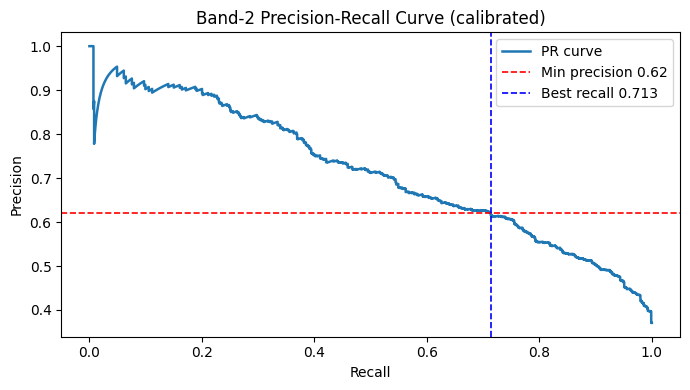

In [ ]:
# =============================================================================
# CELL 13 -- Length of Stay (LOS) Decision Threshold Tuning
# =============================================================================

MIN_PRECISION = 0.62    # raised from 0.50

precisions, recalls, thresholds = precision_recall_curve(
    val_band2_binary, cal_b1_probs
)

best_band2_threshold = 0.5
best_recall          = -1.0

for prec, rec, thr in zip(precisions[:-1], recalls[:-1], thresholds):
    if prec >= MIN_PRECISION and rec > best_recall:
        best_recall          = float(rec)
        best_band2_threshold = float(thr)

print(f'Optimal Band-2 threshold : {best_band2_threshold:.4f}')
print(f'Recall at threshold      : {best_recall:.4f}')

plt.figure(figsize=(7, 4))
plt.plot(recalls, precisions, lw=1.8, label='PR curve')
plt.axhline(MIN_PRECISION, color='red',  lw=1.2, linestyle='--',
            label=f'Min precision {MIN_PRECISION}')
plt.axvline(best_recall,   color='blue', lw=1.2, linestyle='--',
            label=f'Best recall {best_recall:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Band-2 Precision-Recall Curve (calibrated)')
plt.legend()
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'band2_pr_curve.png'), dpi=150)
plt.show()

Optimal mortality threshold : 0.1887
Recall at threshold         : 0.7500


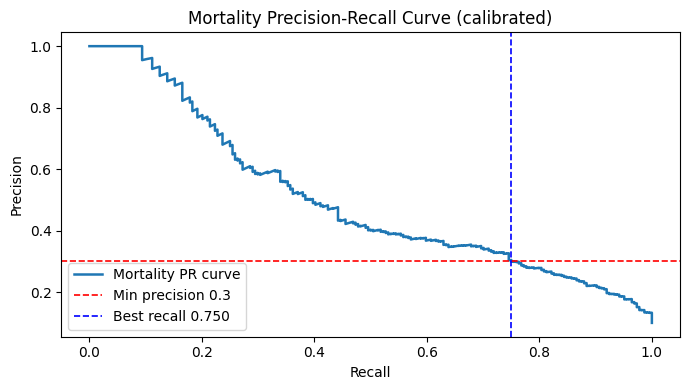

In [ ]:
# =============================================================================
# CELL 14 -- Mortality Decision Threshold Tuning
# =============================================================================

from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

MIN_MORT_PRECISION = 0.30

mort_precisions, mort_recalls, mort_thresholds = precision_recall_curve(
    val_mort_labels_np, cal_mort_probs
)

best_mort_threshold = 0.5    # fallback default
best_mort_recall    = -1.0

for prec, rec, thr in zip(mort_precisions[:-1], mort_recalls[:-1], mort_thresholds):
    if prec >= MIN_MORT_PRECISION and rec > best_mort_recall:
        best_mort_recall    = float(rec)
        best_mort_threshold = float(thr)

print(f'Optimal mortality threshold : {best_mort_threshold:.4f}')
print(f'Recall at threshold         : {best_mort_recall:.4f}')

plt.figure(figsize=(7, 4))
plt.plot(mort_recalls, mort_precisions, lw=1.8, label='Mortality PR curve')
plt.axhline(MIN_MORT_PRECISION, color='red',  lw=1.2, linestyle='--',
            label=f'Min precision {MIN_MORT_PRECISION}')
plt.axvline(best_mort_recall,   color='blue', lw=1.2, linestyle='--',
            label=f'Best recall {best_mort_recall:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Mortality Precision-Recall Curve (calibrated)')
plt.legend()
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'mortality_pr_curve.png'), dpi=150)
plt.show()

In [ ]:
# =============================================================================
# CELL 15 -- Evaluate Calibrated Model on Hold-Out Test Set
# =============================================================================

test_los_logits_list  = []
test_mort_logits_list = []
test_los_labels_list  = []
test_mort_labels_list = []

best_model.eval()
with torch.no_grad():
    for batch in test_loader:
        vitals  = batch['vitals'].to(device)
        tabular = batch['tabular'].to(device)

        los_logits, mort_logit = best_model(vitals, tabular)

        test_los_logits_list.append(los_logits.cpu())
        test_mort_logits_list.append(mort_logit.cpu())
        test_los_labels_list.append(batch['los_label'])
        test_mort_labels_list.append(batch['mortality_label'])

test_los_logits  = torch.cat(test_los_logits_list,  dim=0)
test_mort_logits = torch.cat(test_mort_logits_list, dim=0)
test_los_labels  = torch.cat(test_los_labels_list,  dim=0)
test_mort_labels = torch.cat(test_mort_labels_list, dim=0)

los_metrics  = compute_los_metrics(
    test_los_logits,
    test_los_labels,
    band2_threshold = best_band2_threshold,
)
mort_metrics = compute_mortality_metrics(
    test_mort_logits,
    test_mort_labels,
    threshold = best_mort_threshold,    
)

print('\n-- LOS Metrics (calibrated threshold) -------------------------------------')
for k, v in los_metrics.items():
    print(f'  {k:<22} {v:.4f}')

print('\n-- Mortality Metrics -------------------------------------------------------')
for k, v in mort_metrics.items():
    print(f'  {k:<22} {v:.4f}')

band_preds = ordinal_logits_to_band(
    test_los_logits,
    b0_threshold = 0.5,
    b1_threshold = best_band2_threshold,
).numpy()

print('\n-- LOS Classification Report -----------------------------------------------')
print_classification_report(test_los_labels.numpy(), band_preds)


-- LOS Metrics (calibrated threshold) -------------------------------------
  los_acc                0.5249
  los_macro_f1           0.5101
  los_f1_band0           0.5215
  los_f1_band1           0.3542
  los_f1_band2           0.6546
  los_acc_band0          0.7638
  los_acc_band1          0.2490
  los_acc_band2          0.7143
  los_band2_auroc        0.8020

-- Mortality Metrics -------------------------------------------------------
  mort_auroc             0.8675
  mort_f1                0.4939
  mort_acc               0.8516
  mort_precision         0.3817
  mort_recall            0.6996

-- LOS Classification Report -----------------------------------------------
                 precision    recall  f1-score   support

  Band 0 (<24h)       0.40      0.76      0.52       453
Band 1 (24-72h)       0.61      0.25      0.35       964
  Band 2 (>72h)       0.60      0.71      0.65       833

       accuracy                           0.52      2250
      macro avg       0.54      

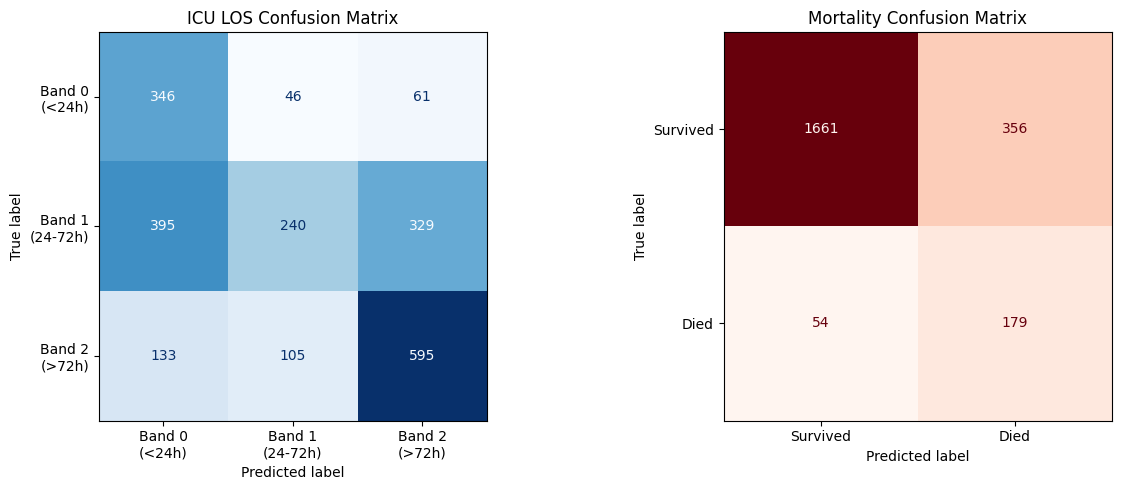

In [ ]:
# =============================================================================
# CELL 16 -- Visualize Test Set Performance (Confusion Matrices)
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_los = confusion_matrix(test_los_labels.numpy(), band_preds)
ConfusionMatrixDisplay(
    cm_los,
    display_labels=['Band 0\n(<24h)', 'Band 1\n(24-72h)', 'Band 2\n(>72h)'],
).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('ICU LOS Confusion Matrix')

mort_preds = (
    calibrated_proba(mort_scaler, test_mort_logits.squeeze(-1).numpy()) > best_mort_threshold
).astype(int)    # was: torch.sigmoid(...) > 0.5

cm_mort = confusion_matrix(test_mort_labels.numpy().astype(int), mort_preds)
ConfusionMatrixDisplay(
    cm_mort,
    display_labels=['Survived', 'Died'],
).plot(ax=axes[1], colorbar=False, cmap='Reds')
axes[1].set_title('Mortality Confusion Matrix')

plt.tight_layout()
plt.savefig(str(FIG_DIR / 'confusion_matrices.png'), dpi=150)
plt.show()

In [ ]:
# =============================================================================
# CELL 17 -- Save Calibrated Model Weights
# =============================================================================

import torch

# Save model state directly — no trainer needed
calibrated_ckpt_path = str(CKPT_DIR / 'best_calibrated.ckpt')
torch.save(best_model.state_dict(), calibrated_ckpt_path)

# Save calibration artifacts
calibration_artifacts = {
    'band2_threshold'     : best_band2_threshold,
    'mortality_threshold' : best_mort_threshold,
    'b1_temperature'      : b1_temp,
    'mort_temperature'    : mort_temp,
}
torch.save(calibration_artifacts, str(CKPT_DIR / 'calibration_artifacts.pt'))

print('Model state dict saved :', calibrated_ckpt_path)
print('Calibration artifacts  :', str(CKPT_DIR / 'calibration_artifacts.pt'))
print()
for k, v in calibration_artifacts.items():
    print(f'  {k:<25} {v}')

Model state dict saved : /content/drive/MyDrive/MP2/outputs/checkpoints/best_calibrated.ckpt
Calibration artifacts  : /content/drive/MyDrive/MP2/outputs/checkpoints/calibration_artifacts.pt

  band2_threshold           0.46967514008198985
  mortality_threshold       0.18872362859015396
  b1_temperature            0.8499214624057816
  mort_temperature          1.7062305177718007


In [ ]:
# =============================================================================
# CELL 18 -- Verify Per-Band AUROC Performance on Test Set
# =============================================================================

import numpy as np
from sklearn.metrics import roc_auc_score

# Convert boundary logits to per-band probabilities
probs   = torch.sigmoid(test_los_logits)
p_ge1   = probs[:, 0].numpy()    # P(LOS >= Band 1)
p_ge2   = probs[:, 1].numpy()    # P(LOS >= Band 2)

p_band0 = 1.0 - p_ge1                      # P(Band 0)
p_band1 = np.clip(p_ge1 - p_ge2, 0, 1)    # P(Band 1)
p_band2 = p_ge2                             # P(Band 2)

labels_np = test_los_labels.numpy().astype(int)

auroc_band0 = roc_auc_score((labels_np == 0).astype(int), p_band0)
auroc_band1 = roc_auc_score((labels_np == 1).astype(int), p_band1)
auroc_band2 = roc_auc_score((labels_np == 2).astype(int), p_band2)
macro_auroc = (auroc_band0 + auroc_band1 + auroc_band2) / 3.0

print('-- Per-Band AUROC (One-vs-Rest) -----------')
print(f'  Band 0  (<24h)   : {auroc_band0:.4f}')
print(f'  Band 1  (24-72h) : {auroc_band1:.4f}')
print(f'  Band 2  (>72h)   : {auroc_band2:.4f}')
print(f'  Macro average    : {macro_auroc:.4f}')

-- Per-Band AUROC (One-vs-Rest) -----------
  Band 0  (<24h)   : 0.8304
  Band 1  (24-72h) : 0.6096
  Band 2  (>72h)   : 0.8020
  Macro average    : 0.7474
